# Benchmark ζ_{i,j} : B&B vs DP pour v1CLD

Compare les deux méthodes de résolution du sous-problème knapsack 1D dans v1CLD :
- **B&B** (`MKPCLDProblem`) — Branch & Bound avec borne de Dantzig, O(n × 2^k)
- **DP**  (`MKPCLDProblemDP`) — Programmation dynamique, O(n × W)

Métriques mesurées :
1. Temps par itération de sous-gradient
2. Qualité de borne L1 en fonction du nombre d'itérations
3. Vitesse de convergence

In [7]:
# ── Paramètres ────────────────────────────────────────────────────────────────
DATASET     = 'data/knapsack/datasets-song/ccmk-song-mknap1_6-S100.txt'
REPLICATION = 0
EPSILON     = 0.10

T_SOLVE     = 200   # itérations par appel solve_v1cld (pour la convergence)
T_BENCH     = 20    # répétitions pour le chrono (T=1 iter chacune)
LOG_EVERY   = 10    # fréquence de log pour les courbes de convergence

In [8]:
import os, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    ROOT = os.path.dirname(os.path.abspath(__vsc_ipynb_file__))
except NameError:
    ROOT = os.getcwd()

sys.path.insert(0, os.path.join(ROOT, 'lib'))
import v1ld_generic_cpp as cpp

def load_song(filepath, replication=0):
    rows = []
    with open(filepath) as f:
        for line in f:
            v = list(map(float, line.strip().split(',')))
            if int(v[4]) != replication: continue
            m, n = int(v[2]), int(v[3])
            A = np.array(v[5:5+m*n]).reshape(m, n)
            b = np.array(v[5+m*n:5+m*n+m])
            c = np.array(v[5+m*n+m:5+m*n+m+n])
            rows.append((A, b, c))
    N = len(rows)
    assert N > 0
    return (rows[0][2], np.ones(N)/N,
            np.stack([r[0] for r in rows]),
            np.stack([r[1] for r in rows]))

c, p, A, b = load_song(os.path.join(ROOT, DATASET), REPLICATION)
N, m, n = A.shape
W_max = int(b.max())
print(f'Instance : {os.path.basename(DATASET)}')
print(f'  n={n}, m={m}, N={N}, ε={EPSILON}')
print(f'  W_max (capacité max) = {W_max}')

Instance : ccmk-song-mknap1_6-S100.txt
  n=39, m=5, N=100, ε=0.1
  W_max (capacité max) = 600


## 1. Chrono : temps par itération

B&B  : 65.669 ± 5.396 ms/iter
DP   : 8.205 ± 0.995 ms/iter
Ratio DP/BB : 0.125x


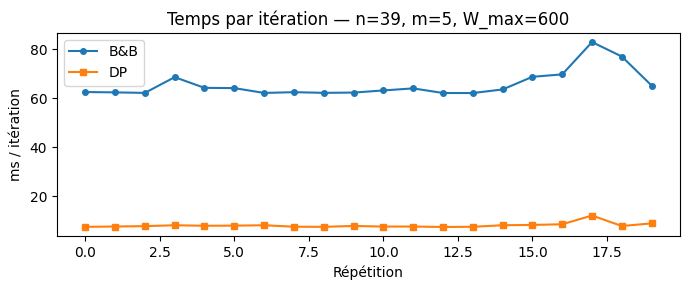

In [9]:
prob_bb = cpp.MKPCLDProblem(c, p, A, b, EPSILON)
prob_dp = cpp.MKPCLDProblemDP(c, p, A, b, EPSILON)

# Warmup
cpp.solve_v1cld(prob_bb, T=2, log_interval=0)
cpp.solve_v1cld(prob_dp, T=2, log_interval=0)

# Chrono T_BENCH × 1 itération
times_bb, times_dp = [], []
for _ in range(T_BENCH):
    t0 = time.perf_counter()
    cpp.solve_v1cld(prob_bb, T=1, log_interval=0)
    times_bb.append((time.perf_counter() - t0) * 1000)

    t0 = time.perf_counter()
    cpp.solve_v1cld(prob_dp, T=1, log_interval=0)
    times_dp.append((time.perf_counter() - t0) * 1000)

ms_bb = np.mean(times_bb)
ms_dp = np.mean(times_dp)
std_bb = np.std(times_bb)
std_dp = np.std(times_dp)

print(f'B&B  : {ms_bb:.3f} ± {std_bb:.3f} ms/iter')
print(f'DP   : {ms_dp:.3f} ± {std_dp:.3f} ms/iter')
print(f'Ratio DP/BB : {ms_dp/ms_bb:.3f}x')

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(times_bb, label='B&B', marker='o', ms=4)
ax.plot(times_dp, label='DP',  marker='s', ms=4)
ax.set_xlabel('Répétition'); ax.set_ylabel('ms / itération')
ax.set_title(f'Temps par itération — n={n}, m={m}, W_max={W_max}')
ax.legend(); plt.tight_layout(); plt.show()

## 2. Convergence : borne L1 vs itérations

Borne finale  B&B : 6641.1615
Borne finale  DP  : 6648.9950
Temps total   B&B : 729.0 ms (200 iters)
Temps total   DP  : 947.3 ms (200 iters)


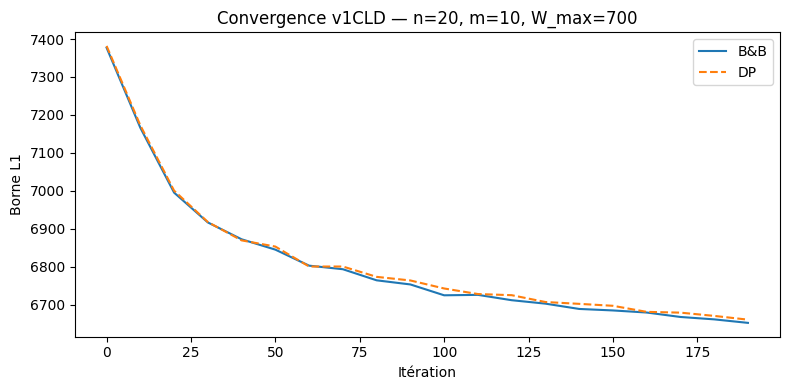

In [ ]:
prob_bb2 = cpp.MKPCLDProblem(c, p, A, b, EPSILON)
prob_dp2 = cpp.MKPCLDProblemDP(c, p, A, b, EPSILON)

r_bb = cpp.solve_v1cld(prob_bb2, T=T_SOLVE, log_interval=LOG_EVERY)
r_dp = cpp.solve_v1cld(prob_dp2, T=T_SOLVE, log_interval=LOG_EVERY)

conv_bb = r_bb['convergence']
conv_dp = r_dp['convergence']
iters   = [i * LOG_EVERY for i in range(len(conv_bb))]

print(f'Borne finale  B&B : {r_bb["v1CLD_star"]:.4f}')
print(f'Borne finale  DP  : {r_dp["v1CLD_star"]:.4f}')
print(f'Temps total   B&B : {r_bb["solve_time_s"]*1000:.1f} ms ({T_SOLVE} iters)')
print(f'Temps total   DP  : {r_dp["solve_time_s"]*1000:.1f} ms ({T_SOLVE} iters)')

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(iters, conv_bb, label='B&B')
ax.plot(iters, conv_dp, label='DP', linestyle='--')
ax.set_xlabel('Itération'); ax.set_ylabel('Borne L1')
ax.set_title(f'Convergence v1CLD — n={n}, m={m}, W_max={W_max}')
ax.legend(); plt.tight_layout(); plt.show()

## 3. Résumé comparatif

In [ ]:
df = pd.DataFrame([
    {'Méthode': 'B&B', 'ms/iter (moy)': f'{ms_bb:.3f}', 'ms/iter (std)': f'{std_bb:.3f}',
     'Borne finale': f'{r_bb["v1CLD_star"]:.4f}',
     'Temps total (ms)': f'{r_bb["solve_time_s"]*1000:.1f}',
     'Complexité': f'O(n × 2^k)  n={n}, k~?'},
    {'Méthode': 'DP',  'ms/iter (moy)': f'{ms_dp:.3f}', 'ms/iter (std)': f'{std_dp:.3f}',
     'Borne finale': f'{r_dp["v1CLD_star"]:.4f}',
     'Temps total (ms)': f'{r_dp["solve_time_s"]*1000:.1f}',
     'Complexité': f'O(n × W)    n={n}, W≤{W_max}'},
])
print(df.to_string(index=False))

Méthode ms/iter (moy) ms/iter (std) Borne finale Temps total (ms)              Complexité
    B&B         3.073         0.214    6641.1615            729.0   O(n × 2^k)  n=20, k~?
     DP         5.939         0.471    6648.9950            947.3 O(n × W)    n=20, W≤700


## 4. Scaling en W (capacité)

Compare le temps en fonction de W pour mettre en évidence O(n×W) du DP vs O(n×2^k) du B&B.

  α=0.10  W_max=    70  BB=1.563ms  DP=2.342ms
  α=0.25  W_max=   175  BB=1.903ms  DP=2.757ms
  α=0.50  W_max=   350  BB=1.974ms  DP=3.756ms
  α=0.75  W_max=   525  BB=2.349ms  DP=4.685ms
  α=1.00  W_max=   700  BB=2.911ms  DP=5.531ms
  α=1.50  W_max=  1050  BB=2.740ms  DP=7.530ms
  α=2.00  W_max=  1400  BB=4.720ms  DP=9.506ms


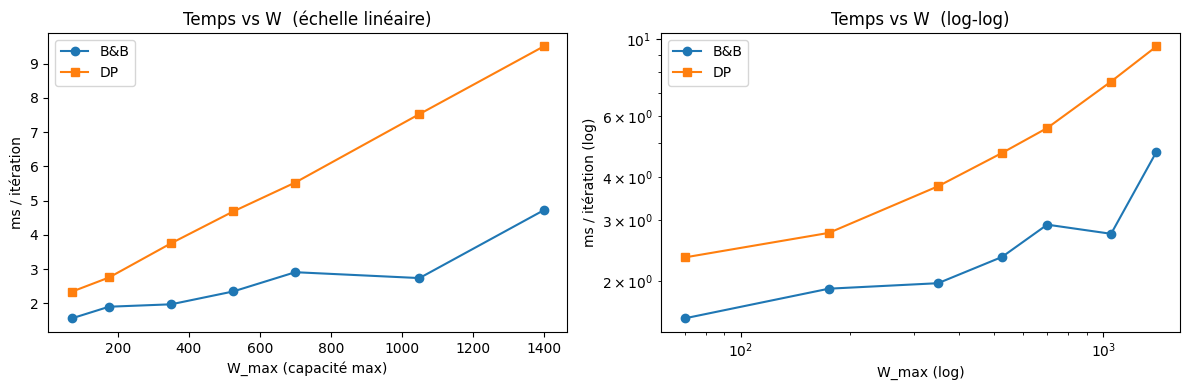

B&B : exposant empirique en W = 0.31  (attendu: BB~0, DP~1)
DP : exposant empirique en W = 0.47  (attendu: BB~0, DP~1)


In [ ]:
# Varie la capacité par un facteur alpha ∈ [0.1, 2.0]
alphas = [0.1, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0]
T_SCALE = 10  # répétitions par point

results = []
for alpha in alphas:
    b_scaled = b * alpha
    W_eff = int(b_scaled.max())

    pb_bb = cpp.MKPCLDProblem(c, p, A, b_scaled, EPSILON)
    pb_dp = cpp.MKPCLDProblemDP(c, p, A, b_scaled, EPSILON)
    cpp.solve_v1cld(pb_bb, T=1, log_interval=0)
    cpp.solve_v1cld(pb_dp, T=1, log_interval=0)

    t0 = time.perf_counter()
    for _ in range(T_SCALE): cpp.solve_v1cld(pb_bb, T=1, log_interval=0)
    ms_b = (time.perf_counter() - t0) / T_SCALE * 1000

    t0 = time.perf_counter()
    for _ in range(T_SCALE): cpp.solve_v1cld(pb_dp, T=1, log_interval=0)
    ms_d = (time.perf_counter() - t0) / T_SCALE * 1000

    results.append({'alpha': alpha, 'W_max': W_eff, 'BB (ms)': ms_b, 'DP (ms)': ms_d})
    print(f'  α={alpha:.2f}  W_max={W_eff:6d}  BB={ms_b:.3f}ms  DP={ms_d:.3f}ms')

df_scale = pd.DataFrame(results)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(df_scale['W_max'], df_scale['BB (ms)'], 'o-', label='B&B')
axes[0].plot(df_scale['W_max'], df_scale['DP (ms)'],  's-', label='DP')
axes[0].set_xlabel('W_max (capacité max)'); axes[0].set_ylabel('ms / itération')
axes[0].set_title('Temps vs W  (échelle linéaire)'); axes[0].legend()

axes[1].plot(df_scale['W_max'], df_scale['BB (ms)'], 'o-', label='B&B')
axes[1].plot(df_scale['W_max'], df_scale['DP (ms)'],  's-', label='DP')
axes[1].set_xscale('log'); axes[1].set_yscale('log')
axes[1].set_xlabel('W_max (log)'); axes[1].set_ylabel('ms / itération (log)')
axes[1].set_title('Temps vs W  (log-log)'); axes[1].legend()

plt.tight_layout(); plt.show()

# Pente log-log → exposant empirique
import numpy as np
w_vals = df_scale['W_max'].values.astype(float)
for method, col in [('B&B', 'BB (ms)'), ('DP', 'DP (ms)')]:
    slope = np.polyfit(np.log(w_vals), np.log(df_scale[col].values), 1)[0]
    print(f'{method} : exposant empirique en W = {slope:.2f}  (attendu: BB~0, DP~1)')